In [23]:
import pandas as pd
import numpy as np

# Read the CSV file
df = pd.read_csv('table.csv', index_col=0)

# Display table dimensions
print(f"Parsing Table Dimensions: {df.shape[0]} states × {df.shape[1]} symbols")
print(f"\nStates: 0-{df.shape[0]-1}")
print(f"Total Columns: {len(df.columns)}")
df

Parsing Table Dimensions: 338 states × 123 symbols

States: 0-337
Total Columns: 123


,TOK_AND,TOK_ARRAY,TOK_ASSIGN,TOK_AUTO,TOK_BEGIN,TOK_BLUR,TOK_BOOL,TOK_CANNY,TOK_COLON,TOK_COMMA,...,RangeExpr,ReturnStmt,Statement,Statements,StructDecl,StructMember,StructMembers,Type,VarDecl,WhileStmt
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,"shift, and go to state 11",NaN,"shift, and go to state 10","shift, and go to state 5",NaN,"shift, and go to state 14",NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,go 27,NaN,NaN,go 24,go 26,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
333,NaN,"shift, and go to state 11",NaN,"shift, and go to state 10",NaN,"shift, and go to state 46","shift, and go to state 14","shift, and go to state 48",NaN,NaN,...,go 77,go 73,go 122,NaN,NaN,NaN,NaN,go 24,go 62,go 68
334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
335,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
336,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Table Statistics
print("="*100)
print("TABLE STATISTICS")
print("="*100)

total_cells = df.shape[0] * df.shape[1]
non_empty = (df != '').sum().sum()
empty = total_cells - non_empty

print(f"Total cells: {total_cells:,}")
print(f"Non-empty cells: {non_empty:,} ({100*non_empty/total_cells:.1f}%)")
print(f"Empty cells: {empty:,} ({100*empty/total_cells:.1f}%)")

# Count by action type - use stack() to convert DataFrame to Series
shift_count = df.stack().astype(str).str.contains('shift', regex=True).sum()
reduce_count = df.stack().astype(str).str.contains('reduce', regex=True).sum()
go_count = df.stack().astype(str).str.contains('^go ', regex=True).sum()

print(f"\nAction breakdown:")
print(f"  Shift actions: {shift_count:,}")
print(f"  Reduce actions: {reduce_count:,}")
print(f"  Go-to actions: {go_count:,}")

TABLE STATISTICS
Total cells: 41,574
Non-empty cells: 41,574 (100.0%)
Empty cells: 0 (0.0%)

Action breakdown:
  Shift actions: 3,123
  Reduce actions: 73
  Go-to actions: 907


In [13]:
# Column Headers (organized by type)
print("\n" + "="*100)
print("COLUMN HEADERS")
print("="*100)

# Separate terminals and non-terminals
terminals = [col for col in df.columns if col.startswith('TOK_')]
non_terminals = [col for col in df.columns if not col.startswith('TOK_')]

print(f"\nTERMINALS ({len(terminals)} tokens):")
for i, term in enumerate(terminals, 1):
    print(f"  {i:2d}. {term}")

print(f"\nNON-TERMINALS ({len(non_terminals)} non-terminals):")
for i, nt in enumerate(non_terminals, 1):
    print(f"  {i:2d}. {nt}")


COLUMN HEADERS

TERMINALS (90 tokens):
   1. TOK_AND
   2. TOK_ARRAY
   3. TOK_ASSIGN
   4. TOK_AUTO
   5. TOK_BEGIN
   6. TOK_BLUR
   7. TOK_BOOL
   8. TOK_CANNY
   9. TOK_COLON
  10. TOK_COMMA
  11. TOK_CONV_OP
  12. TOK_DEC
  13. TOK_DILATE
  14. TOK_DIV
  15. TOK_DIV_ASSIGN
  16. TOK_DO
  17. TOK_DOT
  18. TOK_ELSE
  19. TOK_END
  20. TOK_ENDFOR
  21. TOK_ENDIF
  22. TOK_ENDMATCH
  23. TOK_ENDSTRUCT
  24. TOK_ENDWHILE
  25. TOK_EQ
  26. TOK_ERODE
  27. TOK_FALSE
  28. TOK_FLIP
  29. TOK_FLOAT
  30. TOK_FLOAT_LIT
  31. TOK_FOR
  32. TOK_FOREACH
  33. TOK_FUNCTION
  34. TOK_GEQ
  35. TOK_GRAYSCALE
  36. TOK_GT
  37. TOK_HEX_INT
  38. TOK_HSV
  39. TOK_ID
  40. TOK_IF
  41. TOK_IMAGE
  42. TOK_IN
  43. TOK_INC
  44. TOK_INPUT
  45. TOK_INT
  46. TOK_INT_LIT
  47. TOK_KERNEL
  48. TOK_LBRACKET
  49. TOK_LEQ
  50. TOK_LOAD
  51. TOK_LPAREN
  52. TOK_LT
  53. TOK_MAIN
  54. TOK_MATCH
  55. TOK_MATRIX
  56. TOK_MINUS
  57. TOK_MINUS_ASSIGN
  58. TOK_MOD
  59. TOK_MULT
  60. TOK_MULT_ASSI

In [14]:
# Display first 20 states with sample columns
print("\n" + "="*100)
print("PARSING TABLE - First 20 States (sample columns)")
print("="*100)

# Select columns evenly spaced for display
n_cols = len(df.columns)
step = max(1, n_cols // 12)
sample_cols = [i for i in range(0, n_cols, step)]
if n_cols - 1 not in sample_cols:
    sample_cols.append(n_cols - 1)

sample_df = df.iloc[:20, sample_cols]
print(sample_df.to_string())


PARSING TABLE - First 20 States (sample columns)
   TOK_AND TOK_CONV_OP TOK_ENDIF                    TOK_FOR                  TOK_IMAGE                 TOK_LPAREN TOK_NEQ TOK_RANGE                 TOK_STRING ArgList FuncDecl Param   Type WhileStmt
0      NaN         NaN       NaN                        NaN                        NaN                        NaN     NaN       NaN                        NaN     NaN      NaN   NaN    NaN       NaN
1      NaN         NaN       NaN                        NaN                        NaN                        NaN     NaN       NaN                        NaN     NaN      NaN   NaN    NaN       NaN
2      NaN         NaN       NaN                        NaN                        NaN                        NaN     NaN       NaN                        NaN     NaN      NaN   NaN    NaN       NaN
3      NaN         NaN       NaN                        NaN  shift, and go to state 17                        NaN     NaN       NaN  shift, and go to stat

In [15]:
# View specific state (example: state 5)
state_num = 5
print(f"\n" + "="*100)
print(f"STATE {state_num} - ALL ACTIONS")
print("="*100)

state_actions = df.loc[state_num]
# Filter to show only non-empty actions
non_empty_actions = state_actions[state_actions != '']

if len(non_empty_actions) > 0:
    for symbol, action in non_empty_actions.items():
        print(f"{symbol:25} -> {action}")
else:
    print("No actions for this state")


STATE 5 - ALL ACTIONS
TOK_AND                   -> nan
TOK_ARRAY                 -> shift, and go to state 11
TOK_ASSIGN                -> nan
TOK_AUTO                  -> shift, and go to state 10
TOK_BEGIN                 -> nan
TOK_BLUR                  -> shift, and go to state 46
TOK_BOOL                  -> shift, and go to state 14
TOK_CANNY                 -> shift, and go to state 48
TOK_COLON                 -> nan
TOK_COMMA                 -> nan
TOK_CONV_OP               -> nan
TOK_DEC                   -> nan
TOK_DILATE                -> shift, and go to state 52
TOK_DIV                   -> nan
TOK_DIV_ASSIGN            -> nan
TOK_DO                    -> nan
TOK_DOT                   -> nan
TOK_ELSE                  -> nan
TOK_END                   -> shift, and go to state 30
TOK_ENDFOR                -> nan
TOK_ENDIF                 -> nan
TOK_ENDMATCH              -> nan
TOK_ENDSTRUCT             -> nan
TOK_ENDWHILE              -> nan
TOK_EQ                    -> na

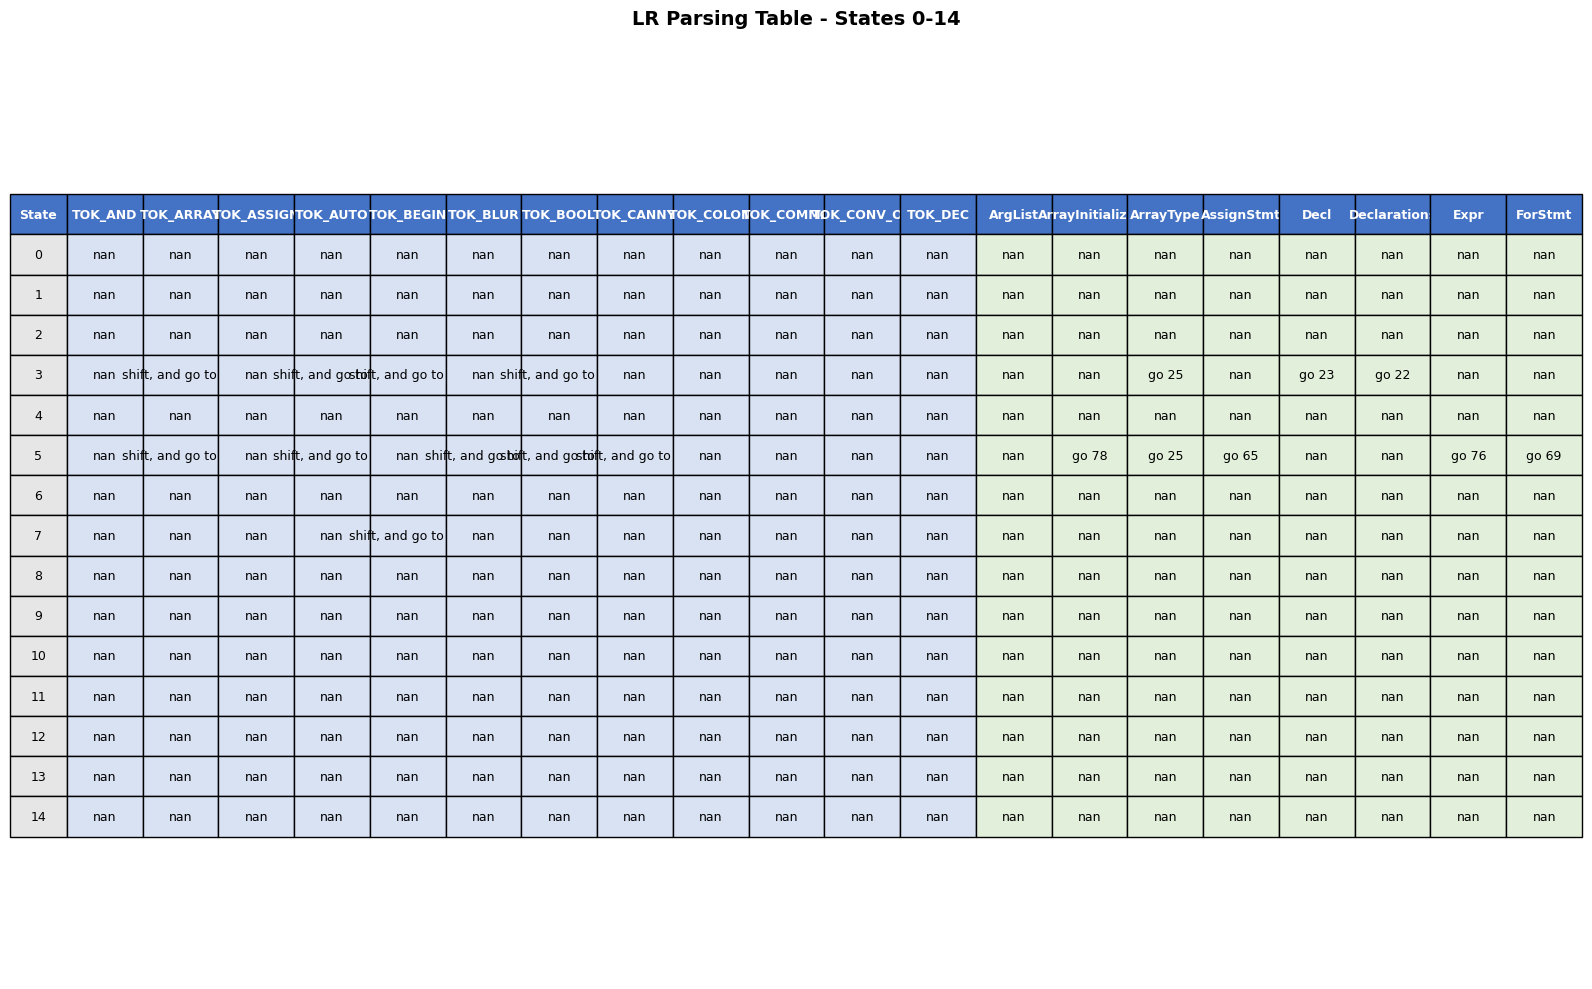

Table image saved as 'parsing_table.png'
Displayed: 15 states, 12 action columns, 8 goto columns


In [16]:
# Create a formatted parsing table (ACTION and GOTO separated)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Separate terminals (ACTION) and non-terminals (GOTO)
terminals = [col for col in df.columns if col.startswith('TOK_')]
non_terminals = [col for col in df.columns if not col.startswith('TOK_')]

# Create a subset for display (first 15 states, selected columns)
n_states_display = 15
n_terms_display = 12
n_nonterms_display = 8

display_terminals = terminals[:n_terms_display]
display_nonterminals = non_terminals[:n_nonterms_display]

# Build display table
table_data = []
for state_idx in df.index[:n_states_display]:
    row = [str(state_idx)]
    
    # Add ACTION columns (terminals)
    for term in display_terminals:
        val = df.loc[state_idx, term]
        row.append(val[:20] if len(str(val)) > 20 else val)  # Truncate long values
    
    # Add GOTO columns (non-terminals)
    for nt in display_nonterminals:
        val = df.loc[state_idx, nt]
        row.append(val[:20] if len(str(val)) > 20 else val)
    
    table_data.append(row)

# Create column headers
col_headers = ['State'] + display_terminals + display_nonterminals

# Create figure and display table
fig, ax = plt.subplots(figsize=(20, 10))
ax.axis('tight')
ax.axis('off')

table = ax.table(cellText=table_data, colLabels=col_headers, cellLoc='center', loc='center',
                colWidths=[0.06] + [0.08]*len(display_terminals) + [0.08]*len(display_nonterminals))

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)

# Color header
for i in range(len(col_headers)):
    table[(0, i)].set_facecolor('#4472C4')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color ACTION and GOTO sections
for i in range(1, len(table_data) + 1):
    table[(i, 0)].set_facecolor('#E7E6E6')
    for j in range(1, len(display_terminals) + 1):
        table[(i, j)].set_facecolor('#D9E2F3')
    for j in range(len(display_terminals) + 1, len(display_terminals) + len(display_nonterminals) + 1):
        table[(i, j)].set_facecolor('#E2EFDA')

plt.title(f'LR Parsing Table - States 0-{n_states_display-1}', fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.savefig('parsing_table.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Table image saved as 'parsing_table.png'")
print(f"Displayed: {n_states_display} states, {len(display_terminals)} action columns, {len(display_nonterminals)} goto columns")


In [19]:
# Display formatted table with styling (browser view)
import pandas as pd

# Prepare data for display
n_states = 20
col_subset_terms = terminals[:10]
col_subset_nonterms = non_terminals[:6]

# Create formatted dataframe
display_df = pd.DataFrame()
for state_idx in df.index[:n_states]:
    row_dict = {}
    for term in col_subset_terms:
        row_dict[term] = df.loc[state_idx, term]
    for nt in col_subset_nonterms:
        row_dict[nt] = df.loc[state_idx, nt]
    display_df = pd.concat([display_df, pd.DataFrame([row_dict])], ignore_index=False)

display_df.index = df.index[:n_states]
display_df.index.name = 'State'

# Apply styling
def highlight_empty(val):
    """Color empty cells light gray"""
    if val == '':
        return 'background-color: #f0f0f0'
    elif any(x in str(val) for x in ['shift', 'go state']):
        return 'background-color: #d9e8f5'
    elif 'reduce' in str(val):
        return 'background-color: #e8f5e9'
    elif 'acc' in str(val):
        return 'background-color: #fff3cd'
    return ''

styled_df = display_df.style.applymap(highlight_empty)
styled_df.set_caption(f'LR Parsing Table - States 0-{n_states-1} (ACTION: Terminals | GOTO: Non-terminals)')

# Display the styled table
styled_df

/var/folders/l6/h8tb9vd12f12th23xrr4hkvh0000gn/T/ipykernel_77027/2581649625.py:35: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_df = display_df.style.applymap(highlight_empty)


,TOK_AND,TOK_ARRAY,TOK_ASSIGN,TOK_AUTO,TOK_BEGIN,TOK_BLUR,TOK_BOOL,TOK_CANNY,TOK_COLON,TOK_COMMA,ArgList,ArrayInitializer,ArrayType,AssignStmt,Decl,Declarations
State,,,,,,,,,,,,,,,,
0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
1,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
2,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
3,nan,"shift, and go to state 11",nan,"shift, and go to state 10","shift, and go to state 5",nan,"shift, and go to state 14",nan,nan,nan,nan,nan,go 25,nan,go 23,go 22
4,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
5,nan,"shift, and go to state 11",nan,"shift, and go to state 10",nan,"shift, and go to state 46","shift, and go to state 14","shift, and go to state 48",nan,nan,nan,go 78,go 25,go 65,nan,nan
6,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
7,nan,nan,nan,nan,"shift, and go to state 80",nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
8,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


In [24]:
# Export to HTML file for best visualization
html_string = """
<html>
<head>
    <style>
        body { font-family: Arial, sans-serif; margin: 20px; }
        h1 { color: #333; }
        table { border-collapse: collapse; width: 100%; margin-top: 20px; }
        th { background-color: #4472C4; color: white; padding: 8px; text-align: center; font-weight: bold; }
        td { border: 1px solid #ddd; padding: 8px; text-align: center; }
        tr:nth-child(even) { background-color: #f9f9f9; }
        .state-col { background-color: #E7E6E6; font-weight: bold; }
        .action-col { background-color: #D9E2F3; }
        .goto-col { background-color: #E2EFDA; }
        .empty-cell { background-color: #FFFFFF; }
    </style>
</head>
<body>
    <h1>LR Parsing Table</h1>
    <p><strong>Total States:</strong> """ + str(len(df)) + """ | <strong>Total Columns:</strong> """ + str(len(df.columns)) + """</p>
    <p><strong>ACTION Columns (Terminals):</strong> """ + str(len(terminals)) + """ | <strong>GOTO Columns (Non-terminals):</strong> """ + str(len(non_terminals)) + """</p>
"""

# Build table
html_string += "<table>\n<thead><tr><th class='state-col'>State</th>"
for term in col_subset_terms:
    html_string += f"<th class='action-col'>{term}</th>"
for nt in col_subset_nonterms:
    html_string += f"<th class='goto-col'>{nt}</th>"
html_string += "</tr></thead>\n<tbody>"

for state_idx in df.index[:n_states]:
    html_string += f"<tr><td class='state-col'>{state_idx}</td>"
    for term in col_subset_terms:
        val = df.loc[state_idx, term]
        cell_class = "empty-cell" if val == '' else "action-col"
        html_string += f"<td class='{cell_class}'>{val}</td>"
    for nt in col_subset_nonterms:
        val = df.loc[state_idx, nt]
        cell_class = "empty-cell" if val == '' else "goto-col"
        html_string += f"<td class='{cell_class}'>{val}</td>"
    html_string += "</tr>\n"

html_string += "</tbody></table>\n</body>\n</html>"

# Save HTML
with open('parsing_table.html', 'w') as f:
    f.write(html_string)

print("For a cleaner view, HTML table saved as 'parsing_table.html'")


For a cleaner view, HTML table saved as 'parsing_table.html'
